# Supernova neutrinos with SNOwGLoBES.jl

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JuliaNeutrino/SNOwGLoBES.jl/blob/main/notebooks/01_supernova_events.ipynb)

SNOwGLoBES.jl computes the events a supernova neutrino burst gives in a detector. It is a Julia port of [SNOwGLoBES](https://github.com/SNOwGLoBES/snowglobes) on top of [GLoBES.jl](https://github.com/JuliaNeutrino/GLoBES.jl): it uses the same detectors, interaction channels, cross sections, smearing matrices and efficiencies, and adds flavour conversion with the Earth crossing, pinched and time-dependent fluences, and CEvNS cross sections.

This notebook goes through a typical workflow: pick a detector, compute the events of a fluence, convert flavours, follow the burst in time, and look at coherent scattering in a xenon detector.

On Colab, choose **Runtime → Change runtime type → Julia** first.

In [ ]:
# Install SNOwGLoBES.jl and GLoBES.jl from GitHub, plus Plots (the first run takes a few minutes).
# On your own computer, skip this cell if they are already installed.
using Pkg
Pkg.add(url = "https://github.com/JuliaNeutrino/GLoBES.jl")
Pkg.add(url = "https://github.com/JuliaNeutrino/SNOwGLoBES.jl")
Pkg.add("Plots")

In [1]:
using SNOwGLoBES, GLoBES, Plots

# One colour per entity, the same in every plot
const BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
const KIND_COLOUR = Dict(:es => BLUE, :cc => ORANGE, :nc => AQUA, :ibd => YELLOW, :cevns => MAGENTA)
default(linewidth = 2, framestyle = :axes, gridalpha = 0.15, legend = :topright, background_color = "#fcfcfb", foreground_color_legend = nothing)

## Detectors and channels

SNOwGLoBES describes a detector by its mass and its number of reference targets per atomic mass unit (free protons for water, ⁴⁰Ar nuclei for argon, ...). The data tables (34 MB) are downloaded the first time they are needed.

In [2]:
detectors()

18-element Vector{Detector}:
 Detector(wc100kt30prct: 100.0 kt, 0.1111 targets per amu)
 Detector(wc100kt15prct: 100.0 kt, 0.1111 targets per amu)
 Detector(ar40kt: 40.0 kt, 0.025 targets per amu)
 Detector(scint20kt: 20.0 kt, 0.1429 targets per amu)
 Detector(halo1: 0.079 kt, 0.004808 targets per amu)
 Detector(halo2: 1.0 kt, 0.004808 targets per amu)
 Detector(novaND: 0.3 kt, 0.107 targets per amu)
 Detector(novaFD: 14.0 kt, 0.107 targets per amu)
 Detector(d2O: 0.001 kt, 0.1 targets per amu)
 Detector(wc100kt30prct_he: 100.0 kt, 0.1111 targets per amu)
 Detector(ar40kt_he: 40.0 kt, 0.025 targets per amu)
 Detector(icecube: 51600.0 kt, 0.1111 targets per amu)
 Detector(km3net: 208098.0 kt, 0.1111 targets per amu)
 Detector(ds20: 0.0386 kt, 0.025 targets per amu)
 Detector(argo: 0.3 kt, 0.025 targets per amu)
 Detector(lz: 0.007 kt, 0.0035 targets per amu)
 Detector(xent: 0.006 kt, 0.0035 targets per amu)
 Detector(pandax: 0.004 kt, 0.0035 targets per amu)

A channel list names the interactions in a material. Each channel has a neutrino flavour and a weight: `nue_e` is ν_e–electron scattering, with 18 electrons per ⁴⁰Ar nucleus.

In [3]:
channels(:argon)

14-element Vector{SNOwGLoBES.Channel}:
 Channel(nue_e: νe, weight 18.0)
 Channel(nuebar_e: ν̄e, weight 18.0)
 Channel(numu_e: νμ, weight 18.0)
 Channel(numubar_e: ν̄μ, weight 18.0)
 Channel(nutau_e: ντ, weight 18.0)
 Channel(nutaubar_e: ν̄τ, weight 18.0)
 Channel(nue_Ar40: νe, weight 1.0)
 Channel(nuebar_Ar40: ν̄e, weight 1.0)
 Channel(nc_nue_Ar40: νe, weight 1.0)
 Channel(nc_numu_Ar40: νμ, weight 1.0)
 Channel(nc_nutau_Ar40: ντ, weight 1.0)
 Channel(nc_nuebar_Ar40: ν̄e, weight 1.0)
 Channel(nc_numubar_Ar40: ν̄μ, weight 1.0)
 Channel(nc_nutaubar_Ar40: ν̄τ, weight 1.0)

## A fluence

The fluence is the time-integrated flux at the detector, in neutrinos per cm² per MeV. SNOwGLoBES comes with a few models; `livermore` is the classic Livermore simulation, for a supernova 10 kpc away.

In [4]:
livermore = fluence(:livermore)

Fluence(501 energies, 0.0–100.0 MeV; ν_e 2.56e+11, ν̄_e 1.88e+11, ν_μ 1.36e+11 per cm²)

In [5]:
mean_energy(livermore)   # MeV

(nue = 11.200170660000326, numu = 21.084409628439467, nutau = 21.084409628439467, nuebar = 15.478610501367855, numubar = 21.084409628439467, nutaubar = 21.084409628439467)

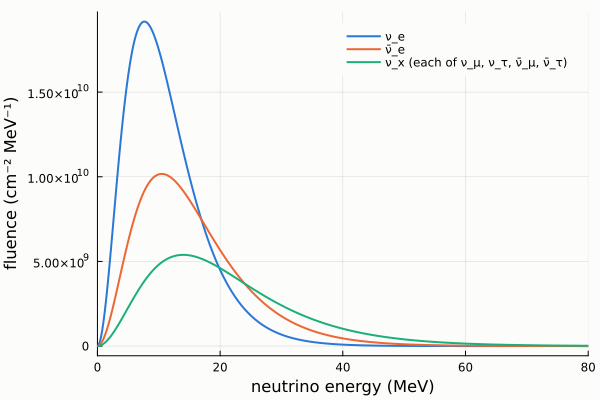

In [6]:
plot(livermore.energies, livermore.nue; label = "ν_e", color = BLUE, xlabel = "neutrino energy (MeV)", ylabel = "fluence (cm⁻² MeV⁻¹)", xlims = (0, 80))
plot!(livermore.energies, livermore.nuebar; label = "ν̄_e", color = ORANGE)
plot!(livermore.energies, livermore.numu; label = "ν_x (each of ν_μ, ν_τ, ν̄_μ, ν̄_τ)", color = AQUA)

## Events in a detector

`SupernovaDetector` reads the cross sections, smearing matrices and efficiencies of a detector and channel list once; `event_rates` then gives the events of any fluence. `ar40kt` is 40 kt of liquid argon, the size of DUNE.

In [7]:
dune = SupernovaDetector(:ar40kt, :argon)
r = event_rates(dune, livermore)

Supernova events in ar40kt (40.0 kt):
  channel               events    detected
  nue_e                 278.41      155.98
  nuebar_e              120.24       55.65
  numu_e                 49.15       35.42
  numubar_e              42.14       29.18
  nutau_e                48.69       35.10
  nutaubar_e             42.48       29.41
  nue_Ar40             2671.93     2647.71
  nuebar_Ar40           224.41      224.36
  nc_nue_Ar40           105.17      103.07
  nc_numu_Ar40          921.26      909.89
  nc_nutau_Ar40         921.26      909.89
  nc_nuebar_Ar40        340.99      336.03
  nc_numubar_Ar40       921.26      909.89
  nc_nutaubar_Ar40      921.26      909.89
  total ES              581.10      340.74
  total CC             2896.35     2872.07
  total NC             4131.20     4078.66
  total                7608.65     7291.47

"events" are the interactions, "detected" the events after the energy resolution and efficiencies. Each channel has both spectra: against the neutrino energy, and against the detected energy.

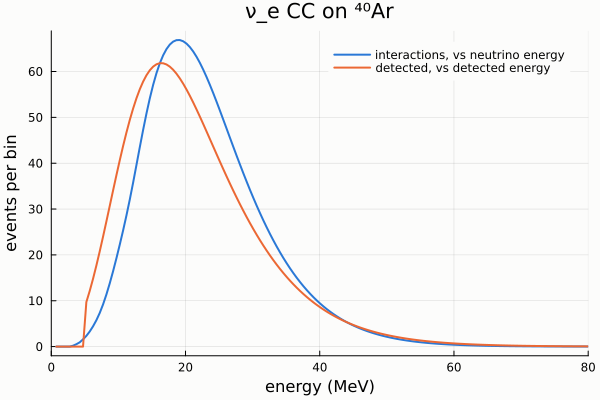

In [8]:
c = r["nue_Ar40"]
plot(c.energies, c.unsmeared; label = "interactions, vs neutrino energy", color = BLUE, xlabel = "energy (MeV)", ylabel = "events per bin", title = "ν_e CC on ⁴⁰Ar", xlims = (0, 80))
plot!(c.detected_energies, c.smeared; label = "detected, vs detected energy", color = ORANGE)

Summed by kind of interaction (`interaction` sorts the channels into CC, NC, elastic scattering, IBD and CEvNS):

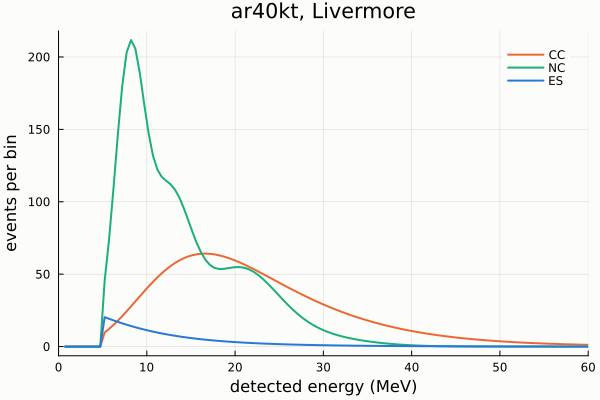

In [9]:
function plot_by_interaction(r; kw...)
    p = plot(; xlabel = "detected energy (MeV)", ylabel = "events per bin", kw...)
    for kind in (:cc, :nc, :es, :ibd)
        chans = [c for c in r if interaction(c.name) === kind]
        isempty(chans) && continue
        plot!(p, chans[1].detected_energies, sum(c.smeared for c in chans); label = uppercase(string(kind)), color = KIND_COLOUR[kind])
    end
    return p
end
plot_by_interaction(r; title = "ar40kt, Livermore", xlims = (0, 60))

The same supernova in a 100 kt water Cherenkov detector (30% photocathode coverage) and a 20 kt scintillator detector, where inverse beta decay on protons dominates:

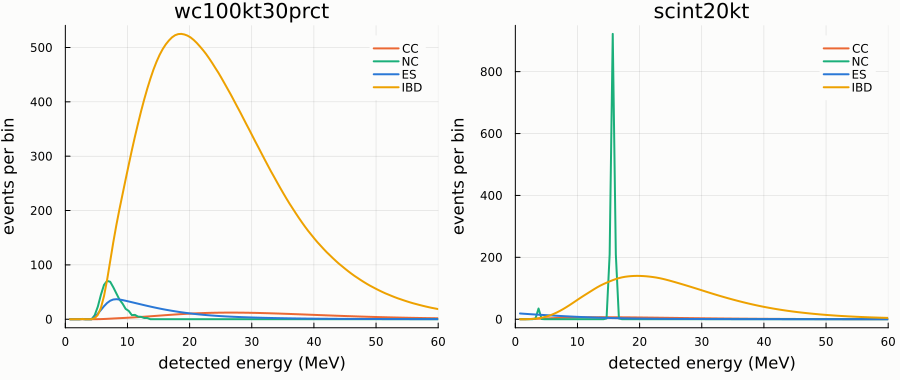

In [10]:
water = event_rates(livermore, :water, :wc100kt30prct)
scint = event_rates(livermore, :scint, :scint20kt)
plot(plot_by_interaction(water; title = "wc100kt30prct", xlims = (0, 60)), plot_by_interaction(scint; title = "scint20kt", xlims = (0, 60)); layout = (1, 2), size = (900, 380), bottom_margin = 5Plots.mm, left_margin = 3Plots.mm)

In [11]:
[(name = d, events = total_events(x)) for (d, x) in ("ar40kt" => r, "wc100kt30prct" => water, "scint20kt" => scint)]

3-element Vector{@NamedTuple{name::String, events::Float64}}:
 (name = "ar40kt", events = 7291.470386399891)
 (name = "wc100kt30prct", events = 29140.831495645954)
 (name = "scint20kt", events = 9194.696029945044)

## Flavour conversion

The fluence of a model is the flux leaving the neutrinosphere. On the way out, the neutrinos cross the MSW resonances of the star and arrive as mass eigenstates: in the normal ordering ν_e leaves as ν_3, which has only |U_e3|² ≈ 2% of ν_e, so most of the detected ν_e were ν_x at production. `oscillate` applies this adiabatic conversion; the sign of `Δm31` sets the ordering.

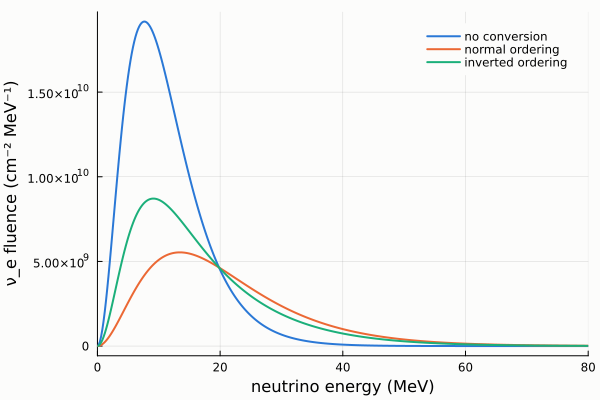

In [12]:
normal = nufit_params("6.1"; ordering = :normal)
inverted = nufit_params("6.1"; ordering = :inverted)
plot(livermore.energies, livermore.nue; label = "no conversion", color = BLUE, xlabel = "neutrino energy (MeV)", ylabel = "ν_e fluence (cm⁻² MeV⁻¹)", xlims = (0, 80))
plot!(livermore.energies, oscillate(livermore, normal).nue; label = "normal ordering", color = ORANGE)
plot!(livermore.energies, oscillate(livermore, inverted).nue; label = "inverted ordering", color = AQUA)

In [13]:
[(conversion = name, ν_e_CC = total_events(event_rates(dune, f)["nue_Ar40"])) for (name, f) in
 ("none" => livermore, "normal" => oscillate(livermore, normal), "inverted" => oscillate(livermore, inverted))]

3-element Vector{@NamedTuple{conversion::String, ν_e_CC::Float64}}:
 (conversion = "none", ν_e_CC = 2647.7105940403103)
 (conversion = "normal", ν_e_CC = 9918.55252343785)
 (conversion = "inverted", ν_e_CC = 7840.875602361135)

A supernova below the horizon is seen through the Earth, whose matter changes the flavour content again (Earth regeneration). `earth_path` is the path length in km through the PREM Earth:

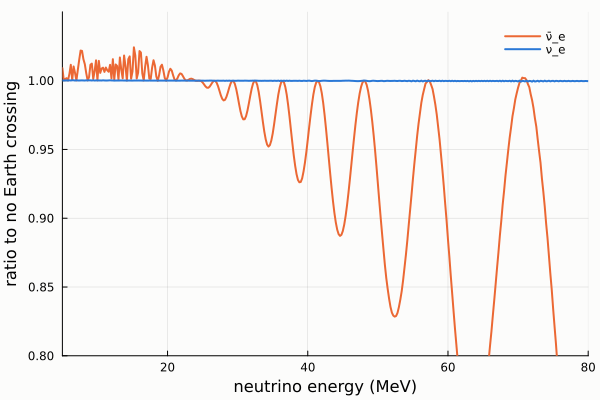

In [14]:
vacuum = oscillate(livermore, normal)
through_earth = oscillate(livermore, normal; earth_path = 10_000)
plot(livermore.energies, through_earth.nuebar ./ vacuum.nuebar; label = "ν̄_e", color = ORANGE, xlabel = "neutrino energy (MeV)", ylabel = "ratio to no Earth crossing", xlims = (5, 80), ylims = (0.8, 1.05))
plot!(livermore.energies, through_earth.nue ./ vacuum.nue; label = "ν_e", color = BLUE)

## Pinched spectra

Simulations are often summarised by the quasi-thermal ("pinched") spectrum of each flavour: a mean energy, a pinching parameter α and a total emitted energy. `pinched_fluence` builds the fluence of a supernova from them; here α = 2 is close to a thermal spectrum and larger α narrows it.

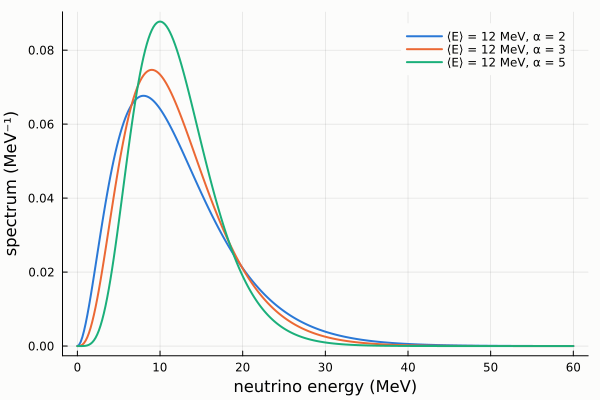

In [15]:
E = 0:0.2:60
plot(; xlabel = "neutrino energy (MeV)", ylabel = "spectrum (MeV⁻¹)")
for (α, colour) in ((2, BLUE), (3, ORANGE), (5, AQUA))
    plot!(E, pinched_spectrum.(E, 12, α); label = "⟨E⟩ = 12 MeV, α = $α", color = colour)
end
plot!()

In [16]:
pinched = pinched_fluence(mean_energy = (10, 13, 15), α = (3, 3, 2.5), total_energy = (5e52, 5e52, 5e52); distance = 10)
event_rates(dune, oscillate(pinched, normal))

Supernova events in ar40kt (40.0 kt):
  channel               events    detected
  nue_e                 255.25      168.50
  nuebar_e              107.84       43.75
  numu_e                 44.75       24.44
  numubar_e              38.42       22.34
  nutau_e                44.33       23.81
  nutaubar_e             38.73       22.30
  nue_Ar40             4120.83     4109.87
  nuebar_Ar40            84.95       84.89
  nc_nue_Ar40           222.13      218.55
  nc_numu_Ar40          141.75      139.27
  nc_nutau_Ar40         130.97      128.63
  nc_nuebar_Ar40        150.90      148.17
  nc_numubar_Ar40       214.07      210.58
  nc_nutaubar_Ar40      202.28      198.94
  total ES              529.33      305.13
  total CC             4205.77     4194.76
  total NC             1062.09     1044.14
  total                5797.19     5544.03

## The burst in time

The Garching model (Hüdepohl et al. 2010) gives pinched spectra in 300 time steps, from the neutronization burst at the bounce to 9 s. `event_rates` takes a vector of fluences and reuses the loaded detector, so the whole time series takes a second or two.

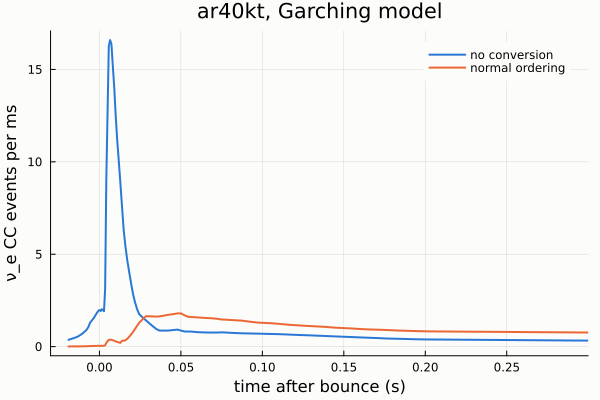

In [17]:
g = garching_fluences()
steps = event_rates(dune, g.fluences)
steps_normal = event_rates(dune, [oscillate(f, normal) for f in g.fluences])
νe_rate(rs) = [total_events(x["nue_Ar40"]) for x in rs] ./ (1000 .* g.duration)   # events per ms
plot(g.time, νe_rate(steps); label = "no conversion", color = BLUE, xlabel = "time after bounce (s)", ylabel = "ν_e CC events per ms", xlims = (-0.03, 0.3), title = "ar40kt, Garching model")
plot!(g.time, νe_rate(steps_normal); label = "normal ordering", color = ORANGE)

The neutronization peak in ν_e at the bounce is the cleanest signature of the mass ordering: in the normal ordering it is converted away. Over the whole burst:

In [18]:
(no_conversion = sum(total_events, steps), normal_ordering = sum(total_events, steps_normal))

(no_conversion = 1336.474991979873, normal_ordering = 1826.8569982378413)

## Coherent scattering in a dark-matter detector

Liquid xenon detectors such as LZ (7 t) see supernova neutrinos through coherent elastic scattering on nuclei (CEvNS), with keV recoils. These channels have their own binning: recoils up to 10 keV.

In [19]:
lz = event_rates(livermore, :xenon_coh, :lz)

Supernova events in lz (0.007 kt):
  channel                   events    detected
  coh_helm_nue_Xe            12.47        8.58
  coh_helm_numu_Xe           16.88       14.38
  coh_helm_nutau_Xe          16.88       14.38
  coh_helm_nuebar_Xe         15.47       12.25
  coh_helm_numubar_Xe        16.88       14.38
  coh_helm_nutaubar_Xe       16.88       14.38
  total CEvNS                95.44       78.36
  total                      95.44       78.36

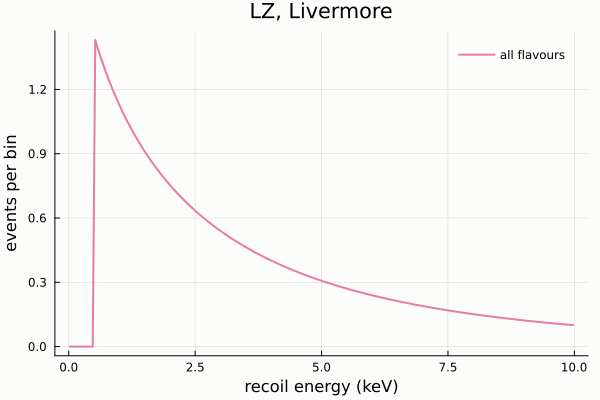

In [20]:
c = lz["coh_helm_numu_Xe"]
plot(1e3 .* c.detected_energies, sum(x.smeared for x in lz); label = "all flavours", color = MAGENTA, xlabel = "recoil energy (keV)", ylabel = "events per bin", title = "LZ, Livermore")

`cevns_cross_section` computes the CEvNS cross section with the Helm (Lewin–Smith radius) or Klein–Nystrand form factor, and the low-energy weak mixing angle. The cross-section tables of SNOwGLoBES are for recoils below 10 keV, the window of its smearing matrices, which is why they fall at high energies:

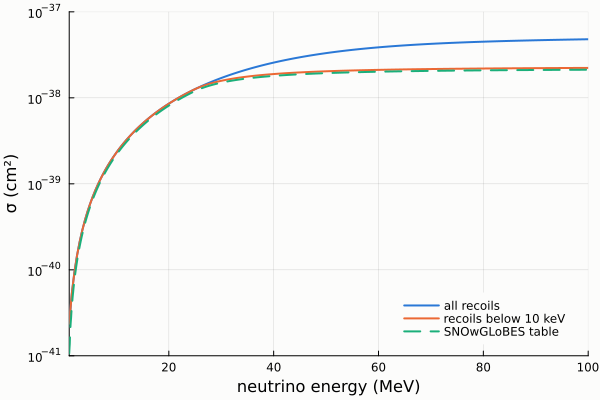

In [21]:
Eν = range(1, 100, 200)
table = cross_section("coh_helm_nue_Xe")
plot(Eν, cevns_cross_section.(Eν, :Xe); label = "all recoils", color = BLUE, xlabel = "neutrino energy (MeV)", ylabel = "σ (cm²)", yscale = :log10, legend = :bottomright)
plot!(Eν, cevns_cross_section.(Eν, :Xe; recoil_max = 0.01); label = "recoils below 10 keV", color = ORANGE)
shown = table.sigma[:, 1] .> 0   # the table starts with zeros
plot!(table.energies[shown], table.sigma[shown, 1]; label = "SNOwGLoBES table", color = AQUA, linestyle = :dash, xlims = (1, 100), ylims = (1e-41, 1e-37))

To use the new cross sections in a detector, pass them as `cross_sections`, with the recoil window of the channels:

In [22]:
chans = channels(:xenon_coh)
xs = Dict(c.name => cevns_cross_sections(:Xe; recoil_max = c.binning.emax) for c in chans)
lz_new = event_rates(livermore, chans, :lz; cross_sections = xs)
(snowglobes_tables = total_events(lz), this_package = total_events(lz_new))

(snowglobes_tables = 78.35770583423242, this_package = 82.47404195386528)

## Backgrounds

For `ar40kt`, SNOwGLoBES has backgrounds at the surface and at 800 and 4850 feet underground, for the time of the burst. They are smeared like a channel and kept apart from the signal:

In [23]:
[(depth = d, background = total_events(event_rates(livermore, :argon, :ar40kt; background = d).background)) for d in ("surf", "0800", "4850")]

3-element Vector{@NamedTuple{depth::String, background::Float64}}:
 (depth = "surf", background = 1.3997055986749998e6)
 (depth = "0800", background = 2930.6389304570694)
 (depth = "4850", background = 5394.784100358692)

## Differences from SNOwGLoBES

- The efficiencies are applied: the default run mode of `supernova.pl` builds their file names from a variable it never sets.
- The high-energy channel lists (`argon_he`, `water_he`, ...) use their 200 MeV binning; SNOwGLoBES ignores the header that sets it.
- The backgrounds are found: `supernova.pl` looks for `bg_chan_<detector>.dat`, which does not exist.
- Flavour conversion keeps θ13 and ν_μ ≠ ν̄_μ fluxes, and computes the Earth crossing that `oscillate_flux` accepts but ignores.
- CEvNS cross sections use the correct speed of light (the SNOwGLoBES script has 2.988×10¹⁰ cm/s), an accurate recoil integral and sin²θ_W = 0.2386.